In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Admin\Downloads\archive (1).zip")

df

,Unnamed: 0,Gender,DOB,Maths,Physics,Chemistry,English,Biology,Economics,History,Civics
0,John,M,05/04/1988,55,45,56.0,87,21,52,89,65
1,Suresh,M,4/5/1987,75,55,NaN,64,90,61,58,2
2,Ramesh,M,25/5/1989,25,54,89.0,76,95,87,56,74
3,Jessica,F,12/8/1990,78,55,86.0,63,54,89,75,45
4,Jennifer,F,2/9/1989,58,96,78.0,46,96,77,83,53


In [2]:

df = df.rename(columns={"Unnamed: 0": "Name"})

df

,Name,Gender,DOB,Maths,Physics,Chemistry,English,Biology,Economics,History,Civics
0,John,M,05/04/1988,55,45,56.0,87,21,52,89,65
1,Suresh,M,4/5/1987,75,55,NaN,64,90,61,58,2
2,Ramesh,M,25/5/1989,25,54,89.0,76,95,87,56,74
3,Jessica,F,12/8/1990,78,55,86.0,63,54,89,75,45
4,Jennifer,F,2/9/1989,58,96,78.0,46,96,77,83,53


In [3]:
df.isnull().sum()
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 1


In [4]:
df.describe()

,Maths,Physics,Chemistry,English,Biology,Economics,History,Civics
count,5.000000,5.000000,4.000000,5.000000,5.000000,5.00000,5.00000,5.000000
mean,58.200000,61.000000,77.250000,67.200000,71.200000,73.20000,72.20000,47.800000
std,21.135279,20.012496,14.908052,15.385058,32.980297,16.22344,14.75466,27.905197
min,25.000000,45.000000,56.000000,46.000000,21.000000,52.00000,56.00000,2.000000
25%,55.000000,54.000000,72.500000,63.000000,54.000000,61.00000,58.00000,45.000000
50%,58.000000,55.000000,82.000000,64.000000,90.000000,77.00000,75.00000,53.000000
75%,75.000000,55.000000,86.750000,76.000000,95.000000,87.00000,83.00000,65.000000
max,78.000000,96.000000,89.000000,87.000000,96.000000,89.00000,89.00000,74.000000


In [5]:
subjects = [
    "Maths",
    "Physics",
    "Chemistry",
    "English",
    "Biology",
    "Economics",
    "History",
    "Civics"
]

MEAN

In [6]:
for subject in subjects:
    print(subject, "Mean =", np.mean(df[subject]))

Maths Mean = 58.2
Physics Mean = 61.0
Chemistry Mean = 77.25
English Mean = 67.2
Biology Mean = 71.2
Economics Mean = 73.2
History Mean = 72.2
Civics Mean = 47.8


In [9]:
for subject in subjects:
    print(subject, "Median =", np.median(df[subject]))

Maths Median = 58.0
Physics Median = 55.0
Chemistry Median = nan
English Median = 64.0
Biology Median = 90.0
Economics Median = 77.0
History Median = 75.0
Civics Median = 53.0


In [11]:
for subject in subjects:
    print(subject, "Standard Deviation =", np.std(df[subject]))

Maths Standard Deviation = 18.903967837467352
Physics Standard Deviation = 17.899720668211557
Chemistry Standard Deviation = 12.910751333675357
English Standard Deviation = 13.760813929415658
Biology Standard Deviation = 29.498474536829868
Economics Standard Deviation = 14.510685717773644
History Standard Deviation = 13.196969349058898
Civics Standard Deviation = 24.959166652755055


Complete descriptive-statistics table (Mean ,Median,Max)

In [13]:
descriptive_stats = pd.DataFrame({
    "Mean": df[subjects].mean(),
    "Median": df[subjects].median(),
    "Standard Deviation": df[subjects].std(),
    "Minimum": df[subjects].min(),
    "Maximum": df[subjects].max()
})

descriptive_stats

,Mean,Median,Standard Deviation,Minimum,Maximum
Maths,58.20,58.0,21.135279,25.0,78.0
Physics,61.00,55.0,20.012496,45.0,96.0
Chemistry,77.25,82.0,14.908052,56.0,89.0
English,67.20,64.0,15.385058,46.0,87.0
Biology,71.20,90.0,32.980297,21.0,96.0
Economics,73.20,77.0,16.223440,52.0,89.0
History,72.20,75.0,14.754660,56.0,89.0
Civics,47.80,53.0,27.905197,2.0,74.0


In [14]:
df["Total_Marks"] = df[subjects].sum(axis=1)

df[["Name", "Total_Marks"]]

,Name,Total_Marks
0,John,470.0
1,Suresh,405.0
2,Ramesh,556.0
3,Jessica,545.0
4,Jennifer,587.0


AVERAGE MARKS OF EACH STUDENT

In [15]:
df["Average_Marks"] = df[subjects].mean(axis=1)

df[["Name", "Average_Marks"]]

,Name,Average_Marks
0,John,58.750000
1,Suresh,57.857143
2,Ramesh,69.500000
3,Jessica,68.125000
4,Jennifer,73.375000


In [17]:
for subject in subjects:
    print(subject, "Highest =", df[subject].max())

Maths Highest = 78
Physics Highest = 96
Chemistry Highest = 89.0
English Highest = 87
Biology Highest = 96
Economics Highest = 89
History Highest = 89
Civics Highest = 74


STUDENT WITH HIGHEST MARKS TOTAL

In [23]:
top_student = df.loc[df["Total_Marks"].idxmax()]

print("Top Student:", top_student["Name"])
print("Total Marks:", top_student["Total_Marks"])

Top Student: Jennifer
Total Marks: 587.0


GENDER WISE ANALYSIS 

In [24]:
gender_analysis = df.groupby("Gender")[subjects].mean()

gender_analysis

,Maths,Physics,Chemistry,English,Biology,Economics,History,Civics
Gender,,,,,,,,
F,68.000000,75.500000,82.0,54.500000,75.000000,83.000000,79.000000,49.0
M,51.666667,51.333333,72.5,75.666667,68.666667,66.666667,67.666667,47.0


AVAERAGE TOTAL MARKS BY GENDER

In [25]:
gender_total = df.groupby("Gender")["Total_Marks"].mean()

gender_total

Gender
F    566.0
M    477.0
Name: Total_Marks, dtype: float64

In [ ]:
CORRELATION ANALYSIS

In [26]:
math_physics_corr = df["Maths"].corr(df["Physics"])

print("Correlation between Maths and Physics:", math_physics_corr)

Correlation between Maths and Physics: 0.033690358155074866


In [27]:
correlation_matrix = df[subjects].corr()

correlation_matrix

,Maths,Physics,Chemistry,English,Biology,Economics,History,Civics
Maths,1.000000,0.033690,-0.152381,-0.375345,-0.236426,-0.206482,0.239543,-0.742136
Physics,0.033690,1.000000,0.227209,-0.873679,0.566272,0.272583,0.246378,0.006715
Chemistry,-0.152381,0.227209,1.000000,-0.468864,0.752286,0.991514,-0.801415,-0.136518
English,-0.375345,-0.873679,-0.468864,1.000000,-0.639629,-0.406853,-0.005727,0.360568
Biology,-0.236426,0.566272,0.752286,-0.639629,1.000000,0.460608,-0.655654,-0.250945
Economics,-0.206482,0.272583,0.991514,-0.406853,0.460608,1.000000,-0.335462,0.293339
History,0.239543,0.246378,-0.801415,-0.005727,-0.655654,-0.335462,1.000000,0.341970
Civics,-0.742136,0.006715,-0.136518,0.360568,-0.250945,0.293339,0.341970,1.000000


In [ ]:
STRONGEST SUBJECT CORREALTION

In [28]:
corr_matrix = df[subjects].corr()

# Remove duplicate/self correlations
corr_pairs = corr_matrix.unstack()

corr_pairs = corr_pairs[
    (corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1))
]

corr_pairs.abs().sort_values(ascending=False).head(10)

Chemistry  Economics    0.991514
Economics  Chemistry    0.991514
English    Physics      0.873679
Physics    English      0.873679
History    Chemistry    0.801415
Chemistry  History      0.801415
           Biology      0.752286
Biology    Chemistry    0.752286
Civics     Maths        0.742136
Maths      Civics       0.742136
dtype: float64

In [ ]:
FILTERING ANALYSIS


In [29]:
maths_above_70 = df[df["Maths"] > 70]

maths_above_70[["Name", "Maths"]]

,Name,Maths
1,Suresh,75
3,Jessica,78


In [30]:
high_performers = df[df["Average_Marks"] > 70]

high_performers[["Name", "Average_Marks"]]

,Name,Average_Marks
4,Jennifer,73.375


In [ ]:
AVERAGE STUDENT MARKS GARPH

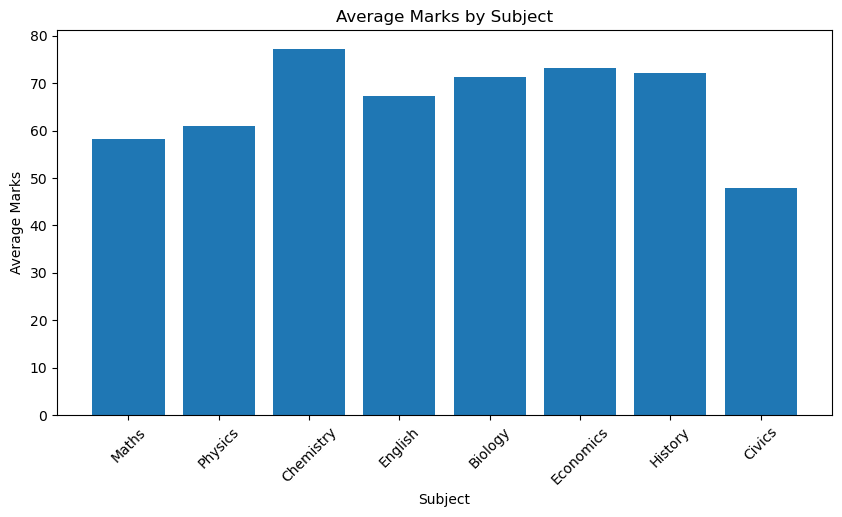

In [31]:
subject_means = df[subjects].mean()

plt.figure(figsize=(10, 5))

plt.bar(subject_means.index, subject_means.values)

plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.title("Average Marks by Subject")

plt.xticks(rotation=45)

plt.show()

In [ ]:
STUDENT TOTAL MARKS GRAPH 

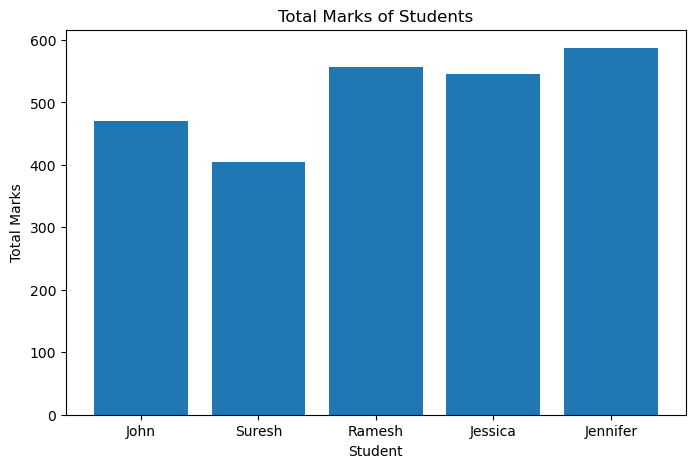

In [32]:
plt.figure(figsize=(8, 5))

plt.bar(df["Name"], df["Total_Marks"])

plt.xlabel("Student")
plt.ylabel("Total Marks")
plt.title("Total Marks of Students")

plt.show()

In [ ]:
CORRELATION HEATMAP

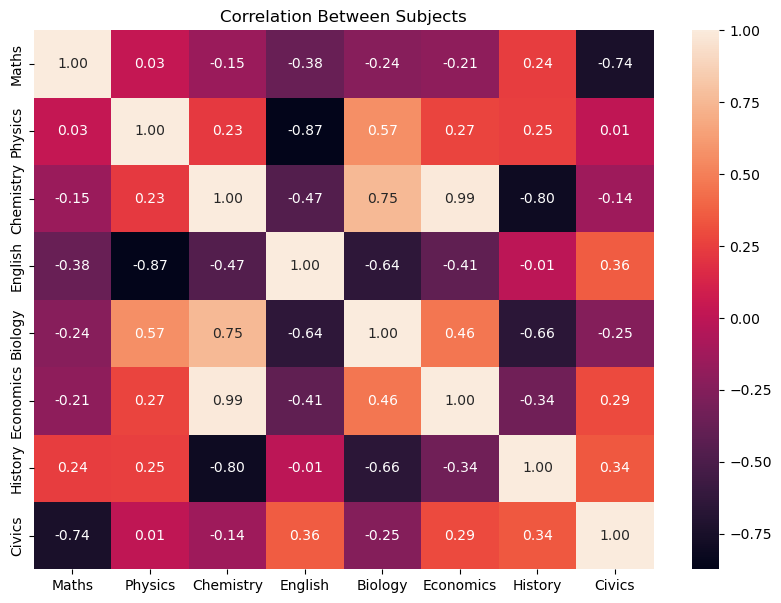

In [33]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[subjects].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Subjects")

plt.show()

In [ ]:
GROUND TRUTH TABLE

In [34]:
ground_truth = {
    "Mean Maths": df["Maths"].mean(),
    "Median Maths": df["Maths"].median(),
    "Mean Physics": df["Physics"].mean(),
    "Mean Chemistry": df["Chemistry"].mean(),
    "Mean English": df["English"].mean(),
    "Mean Biology": df["Biology"].mean(),
    "Mean Economics": df["Economics"].mean(),
    "Mean History": df["History"].mean(),
    "Mean Civics": df["Civics"].mean(),
    "Highest Maths": df["Maths"].max(),
    "Lowest Maths": df["Maths"].min(),
    "Maths-Physics Correlation": df["Maths"].corr(df["Physics"]),
    "Number of Students": len(df)
}

ground_truth

{'Mean Maths': np.float64(58.2),
 'Median Maths': 58.0,
 'Mean Physics': np.float64(61.0),
 'Mean Chemistry': np.float64(77.25),
 'Mean English': np.float64(67.2),
 'Mean Biology': np.float64(71.2),
 'Mean Economics': np.float64(73.2),
 'Mean History': np.float64(72.2),
 'Mean Civics': np.float64(47.8),
 'Highest Maths': 78,
 'Lowest Maths': 25,
 'Maths-Physics Correlation': np.float64(0.033690358155074866),
 'Number of Students': 5}

In [35]:
ground_truth_df = pd.DataFrame(
    ground_truth.items(),
    columns=["Question", "Python_Result"]
)

ground_truth_df

,Question,Python_Result
0,Mean Maths,58.20000
1,Median Maths,58.00000
2,Mean Physics,61.00000
3,Mean Chemistry,77.25000
4,Mean English,67.20000
5,Mean Biology,71.20000
6,Mean Economics,73.20000
7,Mean History,72.20000
8,Mean Civics,47.80000
9,Highest Maths,78.00000


In [37]:
ground_truth_df.to_csv(
    "python_ground_truth.csv",
    index=False
)